# PGD-MaxEnt — minimal working example

**Notation** (consistent with the notes)

| Symbol | Meaning |
|--------|----------|
| $d$ | dimension |
| $\Sigma^*$ | true covariance ($d\times d$, SPD) |
| $S$ | observed index pairs (lower-triangle convention, diagonal always included) |
| $a_{ij}$ | noisy observation at $(i,j)\in S$ |
| $A$ | $d\times d$ matrix: $A_{ij}=a_{ij}$ on $S$, $0$ elsewhere |
| $K(z)$ | precision matrix parameterised by $z\in \mathbb{R}^{\|S\|}$ |
| $\hat\Sigma$ | estimated covariance $= K(z^*)^{-1}$ |

**Algorithm (two stages)**

- **Stage A (PGD):** find the nearest SPD matrix $\tilde X$ whose entries on $S$ fit $A$  
- **Stage B (MaxEnt):** find the max-entropy completion of $\tilde X|_S$ by solving the dual $\min_z \ell(z) = -\log|K(z)| + \operatorname{tr}(K(z)\,\tilde X)$

## Imports

In [99]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import jax
import jax.numpy as jnp
import optax

jax.config.update("jax_enable_x64", True)

In [100]:
def project_psd(X, thresh=1e-8):
    """Project X to the PSD cone by clipping eigenvalues to thresh."""
    vals, vecs = np.linalg.eigh(X)
    return vecs @ np.diag(np.maximum(vals, thresh)) @ vecs.T

## Stage A — Projected Gradient Descent

Minimise the weighted squared-error objective
$$
f(X) = \sum_{(i,j)\in S} \frac{1}{\tau_{ij}^2}(X_{ij}-a_{ij})^2
\quad\text{subject to }X\succeq 0,
$$
where $\tau_{ij}$ is the noise standard deviation for entry $(i,j)$.

**Symmetric rewrite** (for gradient derivation, same value as above):
$$
f(X) = \sum_i \frac{1}{\tau_{ii}^2}(X_{ii}-a_{ii})^2
      + \frac{1}{2}\sum_{(i,j)\in E}\frac{1}{\tau_{ij}^2}(X_{ij}-a_{ij})^2,
$$
where $E=\{(i,j):i\neq j,\,(i,j)\in S\text{ or }(j,i)\in S\}$.  The gradient is
$$
[\nabla f(X)]_{ij} =
\begin{cases}
\dfrac{2}{\tau_{ii}^2}(X_{ii}-a_{ii}) & i=j \\[4pt]
\dfrac{1}{\tau_{ij}^2}(X_{ij}-a_{ij}) & (i,j)\in E \\[4pt]
0 & \text{otherwise.}
\end{cases}
$$

**Weight normalisation.**  Let $w_{ij}=1/\tau_{ij}^2$.  Before running PGD, rescale
$\tilde w_{ij} = w_{ij}/\max_{S} w$.  The normalised objective $\tilde f = f/\max w$
has the same minimiser and makes the step size $\eta$ comparable across problem instances.

In [101]:
def stage_a(A, inds, tau, eta=0.1, n_iters=2000, tol=1e-8, track_kkt=False):
    """
    Inputs
    ------
    A         : (d,d) observation matrix (zero at unobserved entries)
    inds      : (m,2) observed index pairs, lower-triangle including diagonal
    tau       : (m,)  noise std-dev for each entry in inds
    eta       : initial step size
    track_kkt : if True, compute and store KKT diagnostics each iteration
                (requires two eigendecompositions per step — disable for speed)

    Returns
    -------
    X    : (d,d) PSD matrix with X_S ≈ A_S
    hist : list of per-iteration dicts; KKT fields present only if track_kkt=True
    """
    d = A.shape[0]

    # Normalised weights: w̃_k = (1/τ_k²) / max_k(1/τ_k²)
    w = 1.0 / tau ** 2
    w = w / w.max()

    W = np.zeros((d, d))
    W[inds[:, 0], inds[:, 1]] = w
    W[inds[:, 1], inds[:, 0]] = w          # symmetric (no-op for diagonal)
    mask = W > 0

    def objective(X):
        r = X[inds[:, 0], inds[:, 1]] - A[inds[:, 0], inds[:, 1]]
        return np.sum(w * r ** 2)

    # Backtracking line search parameters
    armijo = 0.5    # sufficient decrease constant
    beta   = 0.5    # step size decrease factor on backtrack
    gamma  = 1.05   # step size increase factor after a successful step

    X = project_psd(A.copy())
    hist = []

    for t in range(n_iters):
        # Gradient at current X
        G = np.where(mask, W * (X - A), 0.0)
        G[np.arange(d), np.arange(d)] *= 2
        obj = objective(X)

        # Armijo backtracking line search for PGD.
        # Condition: f(X_new) ≤ f(X) − (armijo/η)‖X_new − X‖²
        for _ in range(50):
            X_new = project_psd(X - eta * G)
            # delta = np.linalg.norm(X_new - X, 'fro')
            # if objective(X_new) <= obj - armijo * delta ** 2 / eta:
            #     break
            predicted_decrease = -np.sum(G * (X_new - X))
            if objective(X_new) <= obj - armijo * predicted_decrease:
                break
            eta *= beta
            if eta < 1e-14:
                break

        delta = np.linalg.norm(X_new - X, 'fro')
        entry = {
            'obj':       obj,
            'delta':     delta,
            'grad_norm': np.linalg.norm(G, 'fro'),
            'eta':       eta,
        }

        if track_kkt:
            # Computed at current X (before the step) where G was evaluated
            entry['min_eig_X']  = np.linalg.eigvalsh(X).min()
            entry['min_eig_G']  = np.linalg.eigvalsh(G).min()
            entry['comp_slack'] = abs(np.sum(G * X))

        hist.append(entry)
        X    = X_new
        eta *= gamma    # modest increase; keeps eta near the local Lipschitz scale

        if delta < tol:
            break

    return X, hist

## Stage B — Maximum Entropy completion

Given the Stage A output $\tilde X$, solve the dual of the max-entropy completion:
$$
\min_{z\in\mathbb{R}^{|S|}} \;\ell(z) = -\log|K(z)| + \operatorname{tr}\bigl(K(z)\,\tilde X\bigr)
$$
Gradient:
$$
\frac{\partial\ell}{\partial z_k} =
\begin{cases}
\tilde X_{ii} - \Sigma_{ii} & i=j \\
2(\tilde X_{ij} - \Sigma_{ij}) & i\neq j
\end{cases},
\qquad \Sigma = K(z)^{-1}.
$$
At the optimum $\hat\Sigma_{ij} = \tilde X_{ij}$ for all $(i,j)\in S$, and $K(z^*)_{ij}=0$ outside $S$.

In [102]:
def build_K(z, inds, d):
    """
    Build the symmetric precision matrix K(z).
    K[i,j] = K[j,i] = z[k]  for (i,j) = inds[k].
    (For diagonal entries the two writes coincide, so K[i,i] = z[k].)
    """
    K = np.zeros((d, d))
    K[inds[:, 0], inds[:, 1]] = z
    K[inds[:, 1], inds[:, 0]] = z
    return K


def stage_b(X_psd, inds, n_iters=500):
    """
    Inputs
    ------
    X_psd  : (d,d) PSD matrix from Stage A  (plays the role of 'a' in the dual)
    inds   : (m,2) observed index pairs

    Returns
    -------
    Sigma_hat : (d,d) max-entropy covariance estimate
    hist      : list of per-iteration dicts:
                  loss            : dual objective -log|K| + tr(K X̃)
                  constraint_viol : rms( Σ̂_S - X̃_S )  (→ 0 at convergence)
                  grad_norm       : ‖∇ℓ(z)‖             (→ 0 at convergence)
                  min_eig_K       : λ_min(K)             (stays > 0 if K remains PD)
    """
    d = X_psd.shape[0]
    rows, cols = inds[:, 0], inds[:, 1]
    diag_mask = rows == cols
    mult = np.where(diag_mask, 1.0, 2.0)

    hist = []

    def loss_and_grad(z):
        K = build_K(z, inds, d)
        sign, logdet_K = np.linalg.slogdet(K)
        if sign <= 0:
            # K is non-PD: return a large value but a *regularised* gradient.
            # Returning zeros here corrupts scipy's cubic line-search interpolation,
            # which uses gradients at both bracket endpoints — a zero gradient looks
            # like a critical point and prevents backtracking.  Instead, shift K to
            # the nearest PD point and return its gradient so the line search knows
            # which direction leads back into the feasible region.
            shift = -np.linalg.eigvalsh(K).min() + 1e-4
            K_reg = K + shift * np.eye(d)
            Sigma_reg = np.linalg.inv(K_reg)
            grad = mult * (X_psd[rows, cols] - Sigma_reg[rows, cols])
            return 1e15, grad
        Sigma = np.linalg.inv(K)
        loss = -logdet_K + np.sum(K * X_psd)
        grad = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        return float(loss), grad

    def callback(z):
        K = build_K(z, inds, d)
        sign, logdet_K = np.linalg.slogdet(K)
        if sign <= 0:
            return
        Sigma = np.linalg.inv(K)
        loss = -logdet_K + np.sum(K * X_psd)
        grad = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        hist.append({
            'loss':            float(loss),
            'constraint_viol': float(np.sqrt(np.mean((Sigma[rows, cols] - X_psd[rows, cols]) ** 2))),
            'grad_norm':       float(np.linalg.norm(grad)),
            'min_eig_K':       float(np.linalg.eigvalsh(K).min()),
        })

    z0 = np.where(diag_mask, 1.0 / np.maximum(X_psd[rows, cols], 1e-6), 0.0)

    result = minimize(
        loss_and_grad, z0,
        method='L-BFGS-B', jac=True,
        callback=callback,
        options={
            'maxiter': n_iters,
            'ftol':    0,
            'gtol':    1e-8,
        },
    )

    K_opt = build_K(result.x, inds, d)
    Sigma_hat = np.linalg.inv(K_opt)
    return Sigma_hat, hist

## Full pipeline

In [103]:
def pgd_maxent(A, inds, tau, eta=0.01, pgd_iters=2000, lbfgs_iters=500, tol=1e-8, track_kkt=False):
    """
    Full pipeline.  Returns (Sigma_hat, hist_a, hist_b).
    track_kkt : passed to stage_a; enables KKT diagnostics at extra compute cost.
    """
    print("Stage A: PGD...")
    X_psd, hist_a = stage_a(A, inds, tau, eta=eta, n_iters=pgd_iters, tol=tol, track_kkt=track_kkt)
    r = X_psd[inds[:, 0], inds[:, 1]] - A[inds[:, 0], inds[:, 1]]
    print(f"  {len(hist_a)} iters | obs residual rms = {np.sqrt(np.mean(r**2)):.2e}"
          f" | min eig = {np.linalg.eigvalsh(X_psd).min():.2e}")

    print("Stage B: MaxEnt (L-BFGS)...")
    Sigma_hat, hist_b = stage_b(X_psd, inds, n_iters=lbfgs_iters)
    print(f"  {len(hist_b)} iters | final loss = {hist_b[-1]['loss']:.4e}"
          f" | constraint viol rms = {hist_b[-1]['constraint_viol']:.2e}")

    return Sigma_hat, X_psd, hist_a, hist_b

## Synthetic problem

In [104]:
def make_problem(
    d           = 8,
    fraction_offdiag = 0.25,     # fraction of off-diagonal entries observed
    tau_diag    = 0.1,      # noise std-dev for all diagonal entries
    num_anneal_phases  = 2,        # decrease off-diagonal τ this many times as we add measurements
    anneal_by   = 2.0,      # multiplicative decrease factor
    seed        = 42,
):
    """
    Returns
    -------
    Sigma_true : (d,d) true covariance
    A          : (d,d) noisy observation matrix (zero at unobserved entries)
    inds       : (m,2) observed pairs, lower-triangle including diagonal
    tau        : (m,)  noise std-dev for each entry in inds
    """
    rng = np.random.default_rng(seed)

    # True covariance
    Q, _ = np.linalg.qr(rng.standard_normal((d, d)))
    eigvals = np.clip(np.exp(rng.standard_normal(d)), 0.1, 10.0)
    Sigma_true = Q @ np.diag(eigvals) @ Q.T

    n_offdiag = int(fraction_offdiag * (d * (d - 1) // 2))

    # Observation index set S
    diag_inds    = [(i, i) for i in range(d)]
    pool         = [(i, j) for i in range(d) for j in range(i + 1, d)]
    chosen       = rng.choice(len(pool), min(n_offdiag, len(pool)), replace=False)
    off_diag_inds = [pool[k] for k in chosen]

    # Noise scales
    tau_offdiag_0 = tau_diag * 2**num_anneal_phases
    tau_offdiag   = [tau_offdiag_0 / anneal_by ** (k // (n_offdiag // num_anneal_phases))
                     for k in range(n_offdiag)]

    inds = np.array(diag_inds + off_diag_inds)
    tau  = np.array([tau_diag] * d + tau_offdiag)

    # Noisy observations
    A = np.zeros((d, d))
    for k, (i, j) in enumerate(inds):
        noise  = rng.normal(0, tau[k])
        A[i, j] = Sigma_true[i, j] + noise
        A[j, i] = A[i, j]

    return Sigma_true, A, inds, tau


# ── Parameters ────────────────────────────────────────────────────────────────
d         = 64
fraction_offdiag = 0.2     # fraction of off-diagonal entries observed
tau_diag  = 0.2           # set this; everything else scales from it

Sigma_true, A, inds, tau = make_problem(d=d, tau_diag=tau_diag, fraction_offdiag=fraction_offdiag)

diag_mask = inds[:, 0] == inds[:, 1]
print(f"d = {d},  |S| = {len(inds)}  ({d} diagonal + {len(inds) - d} off-diagonal)")
print(f"True eigenvalues: {np.linalg.eigvalsh(Sigma_true).round(3)}")
print(f"Noisy eigenvalues: {np.linalg.eigvalsh(A).round(3)}")
print()
print(f"{'k':>3}  {'entry':>7}  {'τ':>7}  {'weight':>8}")
print("-" * 32)
for k, ((i, j), t) in enumerate(zip(inds, tau)):
    label = "diag" if i == j else "off "
    print(f"{k:>3}  ({i},{j}) {label}  {t:>7.4f}  {1/t**2:>8.3f}")

d = 64,  |S| = 467  (64 diagonal + 403 off-diagonal)
True eigenvalues: [ 0.1    0.159  0.177  0.349  0.365  0.368  0.376  0.432  0.445  0.459
  0.465  0.48   0.493  0.504  0.524  0.526  0.544  0.544  0.571  0.673
  0.683  0.704  0.738  0.803  0.807  0.864  0.89   0.916  0.931  1.03
  1.099  1.186  1.223  1.33   1.357  1.419  1.429  1.435  1.457  1.547
  1.578  1.728  1.734  1.748  1.749  1.759  2.081  2.11   2.172  2.265
  2.65   2.746  2.765  2.865  3.086  3.584  3.812  3.986  4.137  4.282
  4.344  6.362  7.348 10.   ]
Noisy eigenvalues: [-3.327 -2.684 -2.411 -2.208 -1.847 -1.684 -1.479 -1.407 -1.32  -1.141
 -0.86  -0.817 -0.553 -0.47  -0.266 -0.12   0.099  0.243  0.305  0.42
  0.484  0.658  0.78   0.889  1.078  1.214  1.267  1.34   1.356  1.505
  1.588  1.613  1.805  1.851  1.949  2.01   2.249  2.319  2.386  2.604
  2.735  2.834  2.886  2.963  3.179  3.272  3.374  3.443  3.661  3.778
  3.826  3.888  4.216  4.334  4.493  4.616  4.756  5.138  5.178  5.463
  5.688  6.36   7.068  7.514]


## Run

In [105]:
Sigma_hat, X_hat, hist_a, hist_b = pgd_maxent(A, inds, tau, pgd_iters=2000, track_kkt=True)

print()
frob_all = np.linalg.norm(Sigma_true - Sigma_hat, 'fro')
obs_rms  = np.sqrt(np.mean((Sigma_true[inds[:,0], inds[:,1]] - Sigma_hat[inds[:,0], inds[:,1]])**2))
print(f"Frobenius error (all entries) : {frob_all:.4f}")
print(f"RMS error on observed entries : {obs_rms:.4f}")
print(f"Min eigenvalue of Sigma_hat   : {np.linalg.eigvalsh(Sigma_hat).min():.4f}")

Stage A: PGD...
  2000 iters | obs residual rms = 1.22e-01 | min eig = 1.00e-08
Stage B: MaxEnt (L-BFGS)...
  500 iters | final loss = -8.3431e+33 | constraint viol rms = 8.79e-01

Frobenius error (all entries) : 19.9462
RMS error on observed entries : 0.6855
Min eigenvalue of Sigma_hat   : -0.0000


## Visualise matrices

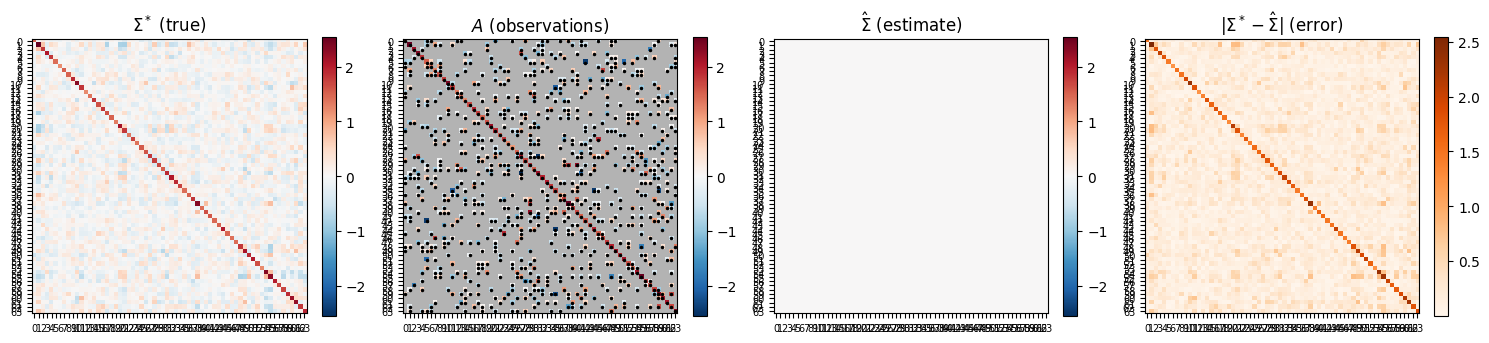

In [106]:
def visualize_pgd_maxent_results():

    # Observed-entry mask (upper triangle for display)
    obs_mask = np.zeros((d, d), dtype=bool)
    obs_mask[inds[:, 0], inds[:, 1]] = True
    obs_mask[inds[:, 1], inds[:, 0]] = True

    vmin = min(Sigma_true.min(), Sigma_hat.min())
    vmax = max(Sigma_true.max(), Sigma_hat.max())

    fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))

    titles  = [r"$\Sigma^*$ (true)", r"$A$ (observations)",
            r"$\hat\Sigma$ (estimate)", r"$|\Sigma^* - \hat\Sigma|$ (error)"]

    v = np.max(np.abs(Sigma_true))

    # Panel 1: true covariance
    im = axes[0].imshow(Sigma_true, vmin=-v, vmax=v, cmap='RdBu_r')
    axes[0].set_title(titles[0])
    plt.colorbar(im, ax=axes[0], fraction=0.046)


    # Panel 2: observations — show only the observed entries; grey out the rest
    A_display = np.full((d, d), np.nan)
    A_display[obs_mask] = A[obs_mask]
    axes[1].imshow(np.ones((d, d)), cmap='Greys', vmin=0, vmax=1, alpha=0.3)   # grey background
    im2 = axes[1].imshow(A_display, vmin=-v, vmax=v, cmap='RdBu_r')       # observed values
    # Mark observed entries with a dot
    for (i, j) in inds:
        axes[1].plot(j, i, 'k.', markersize=3)
        if i != j:
            axes[1].plot(i, j, 'k.', markersize=3)
    axes[1].set_title(titles[1])
    plt.colorbar(im2, ax=axes[1], fraction=0.046)

    # Panel 3: estimate
    im3 = axes[2].imshow(Sigma_hat, vmin=-v, vmax=v, cmap='RdBu_r')
    axes[2].set_title(titles[2])
    plt.colorbar(im3, ax=axes[2], fraction=0.046)

    # Panel 4: absolute error
    err = np.abs(Sigma_true - Sigma_hat)
    im4 = axes[3].imshow(err, cmap='Oranges')
    axes[3].set_title(titles[3])
    plt.colorbar(im4, ax=axes[3], fraction=0.046)

    for ax in axes:
        ax.set_xticks(range(d))
        ax.set_yticks(range(d))
        ax.tick_params(labelsize=7)

    plt.tight_layout()
    plt.show()

visualize_pgd_maxent_results()

## Per-iteration diagnostics

KKT residuals at final iterate:
  min eig X        = 1.000e-08   (≥ 0 required)
  min eig ∇f̃(X)    = -8.202e-04   (≥ 0 required)
  |⟨∇f̃(X), X⟩|     = 2.372e-02   (= 0 required)


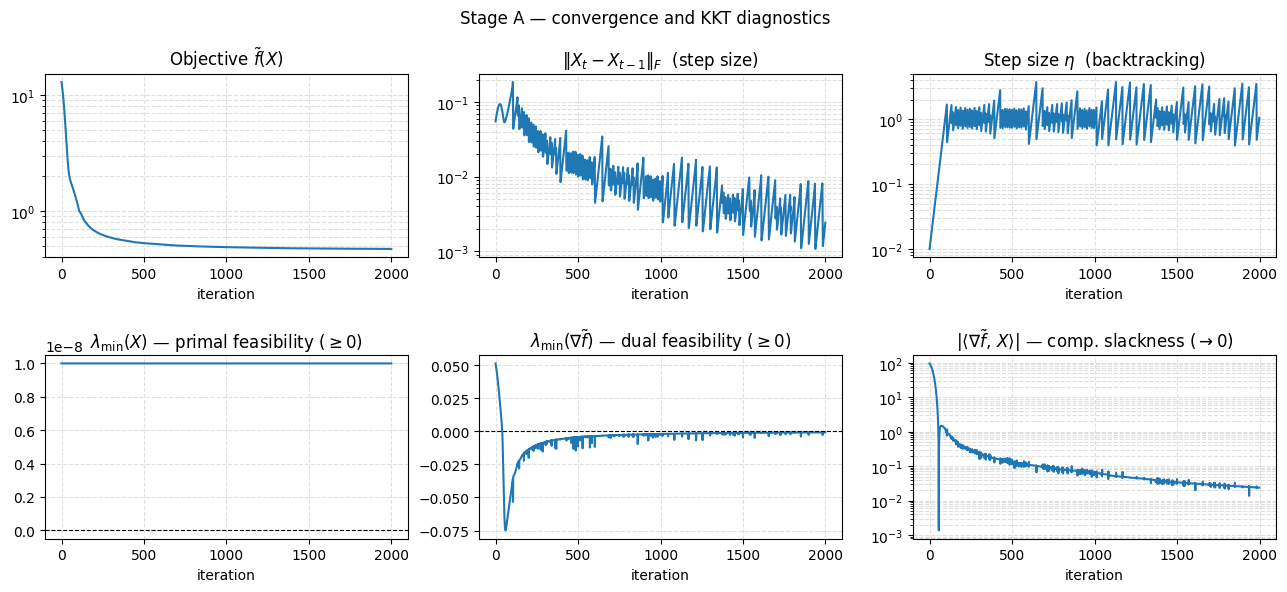

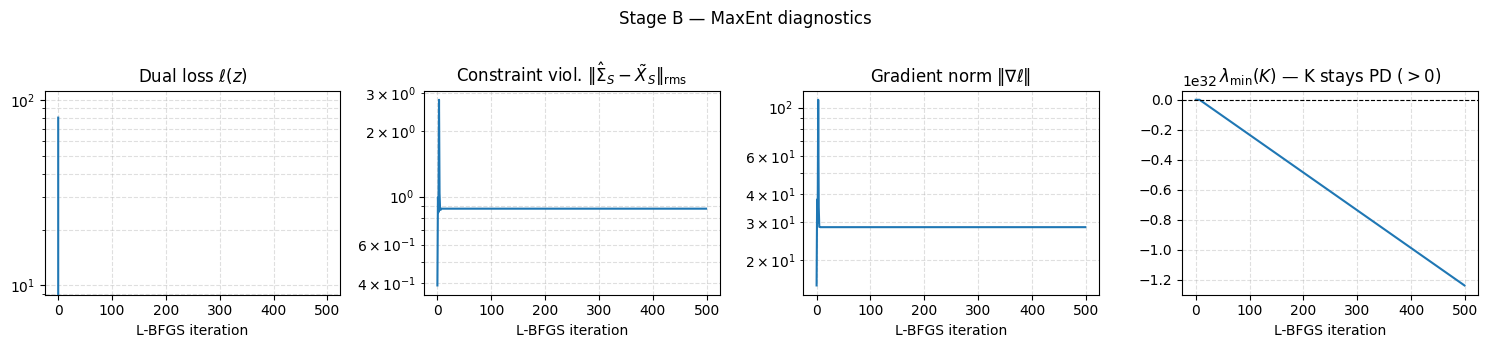

Stage B summary at convergence:
  log|Σ̂|  (entropy)   = -4643.5217
  min eig K           = -1.24e+32
  constraint viol rms = 8.79e-01
  gradient norm       = 2.83e+01


In [107]:
def pgd_diagnostics():

    iters = range(len(hist_a))
    obj        = [h['obj']        for h in hist_a]
    delta      = [h['delta']      for h in hist_a]
    eta_vals   = [h['eta']        for h in hist_a]
    has_kkt    = 'min_eig_X' in hist_a[0]

    fig, axes = plt.subplots(2, 3, figsize=(13, 6))
    fig.suptitle("Stage A — convergence and KKT diagnostics", fontsize=12)

    # ── top row: standard convergence ────────────────────────────────────────────
    axes[0, 0].semilogy(iters, obj)
    axes[0, 0].set_title("Objective $\\tilde{f}(X)$")

    axes[0, 1].semilogy(iters, delta)
    axes[0, 1].set_title(r"$\|X_t - X_{t-1}\|_F$  (step size)")

    axes[0, 2].semilogy(iters, eta_vals)
    axes[0, 2].set_title(r"Step size $\eta$  (backtracking)")

    # ── bottom row: KKT residuals ─────────────────────────────────────────────────
    if has_kkt:
        min_eig_X  = [h['min_eig_X']  for h in hist_a]
        min_eig_G  = [h['min_eig_G']  for h in hist_a]
        comp_slack = [h['comp_slack'] for h in hist_a]

        axes[1, 0].plot(iters, min_eig_X)
        axes[1, 0].axhline(0, color='k', linewidth=0.8, linestyle='--')
        axes[1, 0].set_title(r"$\lambda_{\min}(X)$ — primal feasibility ($\geq 0$)")

        axes[1, 1].plot(iters, min_eig_G)
        axes[1, 1].axhline(0, color='k', linewidth=0.8, linestyle='--')
        axes[1, 1].set_title(r"$\lambda_{\min}(\nabla\tilde{f})$ — dual feasibility ($\geq 0$)")

        axes[1, 2].semilogy(iters, np.maximum(comp_slack, 1e-16))
        axes[1, 2].set_title(r"$|\langle\nabla\tilde{f},\,X\rangle|$ — comp. slackness ($\to 0$)")

        print("KKT residuals at final iterate:")
        print(f"  min eig X        = {min_eig_X[-1]:.3e}   (≥ 0 required)")
        print(f"  min eig ∇f̃(X)    = {min_eig_G[-1]:.3e}   (≥ 0 required)")
        print(f"  |⟨∇f̃(X), X⟩|     = {comp_slack[-1]:.3e}   (= 0 required)")
    else:
        for ax in axes[1]:
            ax.text(0.5, 0.5, "track_kkt=False", transform=ax.transAxes,
                    ha='center', va='center', color='grey')

    for ax in axes.flat:
        ax.set_xlabel("iteration")
        ax.grid(True, which='both', linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()

def maxent_diagnostics():
    iters_b = range(len(hist_b))

    fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
    fig.suptitle("Stage B — MaxEnt diagnostics", fontsize=12)

    axes[0].semilogy(iters_b, [h['loss']            for h in hist_b])
    axes[0].set_title(r"Dual loss $\ell(z)$")

    axes[1].semilogy(iters_b, [h['constraint_viol'] for h in hist_b])
    axes[1].set_title(r"Constraint viol. $\|\hat\Sigma_S - \tilde X_S\|_{\rm rms}$")

    axes[2].semilogy(iters_b, [h['grad_norm']       for h in hist_b])
    axes[2].set_title(r"Gradient norm $\|\nabla\ell\|$")

    axes[3].plot(iters_b, [h['min_eig_K'] for h in hist_b])
    axes[3].axhline(0, color='k', linewidth=0.8, linestyle='--')
    axes[3].set_title(r"$\lambda_{\min}(K)$ — K stays PD ($> 0$)")

    for ax in axes:
        ax.set_xlabel("L-BFGS iteration")
        ax.grid(True, which='both', linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()

    # Entropy is only meaningful at convergence (dual iterates are not primal-feasible)
    logdet_Sigma_hat = np.linalg.slogdet(Sigma_hat)[1]
    print("Stage B summary at convergence:")
    print(f"  log|Σ̂|  (entropy)   = {logdet_Sigma_hat:.4f}")
    print(f"  min eig K           = {hist_b[-1]['min_eig_K']:.2e}")
    print(f"  constraint viol rms = {hist_b[-1]['constraint_viol']:.2e}")
    print(f"  gradient norm       = {hist_b[-1]['grad_norm']:.2e}")

pgd_diagnostics()
maxent_diagnostics()

## Interior Point Method

Minimise $\phi_\mu(X) = f(X) - \mu\log|X|$ over $X \succ 0$, decreasing $\mu \to 0$.  Since the barrier $-\log|X|$ equals (up to sign) the Gaussian entropy, the central path converges directly to the **max-entropy** solution.

Two parameterisations are provided as separate functions (rather than one function with a flag), because the gradient computations are fundamentally different and merging them would obscure both:

| | `ipm_chol` | `ipm_lowertriang` |
|---|---|---|
| Parameters | lower triangle of $L$, $X=LL^T$ | lower triangle of $X$ directly |
| Convexity | non-convex in $L$ | convex in $z$ |
| PD guarantee | bounds $L_{ii} \ge \varepsilon$ | log-barrier + line-search rejection |
| Gradient cost | $O(|S|d)$ — **no inverse** | $O(d^3)$ — requires $X^{-1}$ |
| Key identity | $\log|LL^T| = 2\sum_i \log L_{ii}$ → barrier gradient is diagonal-only | standard chain rule |

In [108]:
def ipm_chol(A, inds, tau, mu0=1.0, rho=0.5, eps=1e-6, eps_coarse=1e-2, max_outer=40, max_inner=200):
    """
    IPM with Cholesky parameterisation X = L Lᵀ  (L lower triangular, L[i,i] > 0).

    Gradient of φ_μ = f(X) - μ log|X| w.r.t. L (lower triangle):
      ∂φ/∂L[i,j] = 2(G·L)[i,j]                    off-diagonal (i > j)
      ∂φ/∂L[i,i] = 2(G·L)[i,i] − 2μ/L[i,i]        diagonal

    Key: log|LLᵀ| = 2 Σᵢ log L[i,i], so the barrier gradient is diagonal-only
    — no matrix inverse required.  G·L costs O(|S|·d) if G is treated as sparse.

    X ≻ 0 is guaranteed by the bound L[i,i] ≥ ε (no PD check needed).
    Note: φ_μ is non-convex in L; in practice this is not an issue.
    """
    d = A.shape[0]
    rows_obs, cols_obs = inds[:, 0], inds[:, 1]
    diag_d = np.arange(d)

    w = 1.0 / tau ** 2
    w /= w.max()
    W = np.zeros((d, d))
    W[rows_obs, cols_obs] = w
    W[cols_obs, rows_obs] = w
    mask = W > 0

    tril_r, tril_c = np.tril_indices(d)
    is_diag = (tril_r == tril_c)

    bounds = [(1e-8, None) if is_diag[k] else (None, None) for k in range(len(tril_r))]

    def vec_to_L(z):
        L = np.zeros((d, d))
        L[tril_r, tril_c] = z
        return L

    # Initialise: X₀ = α I  →  L₀ = √α I
    alpha = max(float(np.mean(np.abs(np.diag(A)))), 1.0)
    z = np.where(is_diag, np.sqrt(alpha), 0.0)

    mu = mu0
    hist = []

    for _outer in range(max_outer):
        eps_inner = min(mu, eps_coarse)

        def phi_and_grad(z, _mu=mu):
            L = vec_to_L(z)
            diag_L = L[diag_d, diag_d]

            # log|LLᵀ| = 2 Σᵢ log L[i,i]  — O(d), no eigendecomposition
            logdet = 2.0 * np.sum(np.log(diag_L))

            X = L @ L.T
            r = X[rows_obs, cols_obs] - A[rows_obs, cols_obs]
            fval = float(np.sum(w * r ** 2))

            G = np.where(mask, W * (X - A), 0.0)
            G[diag_d, diag_d] *= 2

            # Gradient w.r.t. lower triangle of L:
            #   ∂φ/∂L = 2·(G·L)  with diagonal adjusted for barrier
            # Barrier contributes only on diagonal (log|X| = 2Σ log L[i,i])
            # G·L costs O(|S|·d) with sparse G; here dense for simplicity
            GL = G @ L
            grad_z = 2.0 * GL[tril_r, tril_c]
            grad_z[is_diag] -= 2.0 * _mu / diag_L

            return float(fval - _mu * logdet), grad_z

        result = minimize(phi_and_grad, z, method='L-BFGS-B', jac=True,
                          bounds=bounds,
                          options={'maxiter': max_inner, 'ftol': 0, 'gtol': eps_inner})
        z = result.x
        L_opt = vec_to_L(z)
        X = L_opt @ L_opt.T

        # Diagnostics
        r = X[rows_obs, cols_obs] - A[rows_obs, cols_obs]
        fval = float(np.sum(w * r ** 2))
        G = np.where(mask, W * (X - A), 0.0)
        G[diag_d, diag_d] *= 2
        logdet = 2.0 * np.sum(np.log(z[is_diag]))   # cheap, from L diagonal

        hist.append({
            'mu':          mu,
            'obj':         fval,
            'entropy':     logdet,
            'obs_rms':     float(np.sqrt(np.mean(r ** 2))),
            'inner_iters': result.nit,
            'min_eig_X':   float(np.linalg.eigvalsh(X).min()),
            'min_eig_G':   float(np.linalg.eigvalsh(G).min()),
            'comp_slack':  float(abs(np.sum(G * X))),
        })

        if mu <= eps:
            break
        mu *= rho

    return project_psd(X), hist


# THIS VERSION NOT USED - WAS NOT YET ABLE TO MAKE IT STABLE/CORRECT
def ipm_lowertriang(A, inds, tau, mu0=1.0, rho=0.5, eps=1e-6, eps_coarse=1e-2, max_outer=40, max_inner=200):
    """
    IPM with lower-triangle parameterisation of X directly.

    Gradient of φ_μ = f(X) - μ log|X| w.r.t. lower triangle of X:
      ∂φ/∂z_k = mult_k · (G − μ X⁻¹)[i_k, j_k]
    where mult_k = 1 (diagonal), 2 (off-diagonal) — standard chain rule.

    Requires X⁻¹ each inner step: O(d³).  Convex in z.

    Stability note: X can drift near the PSD boundary as μ → 0 (the barrier
    weakens and X⁻¹ blows up).  This is structurally more fragile than ipm_chol
    where L[i,i] ≥ ε keeps X bounded away from singular.  When a trial step
    leaves the PSD cone we return a regularised gradient (not zeros) so that
    scipy's cubic line-search interpolation backtracks correctly.
    """
    d = A.shape[0]
    rows_obs, cols_obs = inds[:, 0], inds[:, 1]
    diag_d = np.arange(d)

    w = 1.0 / tau ** 2
    w /= w.max()
    W = np.zeros((d, d))
    W[rows_obs, cols_obs] = w
    W[cols_obs, rows_obs] = w
    mask = W > 0

    tril_r, tril_c = np.tril_indices(d)
    mult = np.where(tril_r != tril_c, 2.0, 1.0)

    def vec_to_sym(z):
        X = np.zeros((d, d))
        X[tril_r, tril_c] = z
        X = X + X.T
        X[diag_d, diag_d] /= 2
        return X

    def _grad_at(X_eval, _mu):
        """Gradient of φ_μ at X_eval (assumed PD or regularised to be PD)."""
        G = np.where(mask, W * (X_eval - A), 0.0)
        G[diag_d, diag_d] *= 2
        return mult * (G - _mu * np.linalg.inv(X_eval))[tril_r, tril_c]

    # Initialise: X₀ = α I
    alpha = max(float(np.mean(np.abs(np.diag(A)))), 1.0)
    z = np.where(tril_r == tril_c, alpha, 0.0).astype(float)

    mu = mu0
    hist = []

    for _outer in range(max_outer):
        eps_inner = min(mu, eps_coarse)

        def phi_and_grad(z, _mu=mu):
            X = vec_to_sym(z)
            sign, logdet = np.linalg.slogdet(X)
            if sign <= 0:
                # Regularise to nearest PD point and return its gradient.
                # Returning zeros here would corrupt scipy's cubic line-search
                # interpolation (which uses gradients at both bracket endpoints).
                shift = -np.linalg.eigvalsh(X).min() + 1e-4
                X_reg = X + shift * np.eye(d)
                return 1e300, _grad_at(X_reg, _mu)
            r = X[rows_obs, cols_obs] - A[rows_obs, cols_obs]
            fval = float(np.sum(w * r ** 2))
            G = np.where(mask, W * (X - A), 0.0)
            G[diag_d, diag_d] *= 2
            grad_z = mult * (G - _mu * np.linalg.inv(X))[tril_r, tril_c]
            return float(fval - _mu * logdet), grad_z

        result = minimize(phi_and_grad, z, method='L-BFGS-B', jac=True,
                          options={'maxiter': max_inner, 'ftol': 0, 'gtol': eps_inner})
        z = result.x
        X = vec_to_sym(z)

        # Diagnostics
        r = X[rows_obs, cols_obs] - A[rows_obs, cols_obs]
        fval = float(np.sum(w * r ** 2))
        G = np.where(mask, W * (X - A), 0.0)
        G[diag_d, diag_d] *= 2
        sign, logdet = np.linalg.slogdet(X)

        hist.append({
            'mu':          mu,
            'obj':         fval,
            'entropy':     float(logdet) if sign > 0 else -np.inf,
            'obs_rms':     float(np.sqrt(np.mean(r ** 2))),
            'inner_iters': result.nit,
            'min_eig_X':   float(np.linalg.eigvalsh(X).min()),
            'min_eig_G':   float(np.linalg.eigvalsh(G).min()),
            'comp_slack':  float(abs(np.sum(G * X))),
        })

        if mu <= eps:
            break
        mu *= rho

    return project_psd(X), hist

In [109]:
Sigma_ipm, hist_ipm = ipm_chol(A, inds, tau, eps=1e-2)

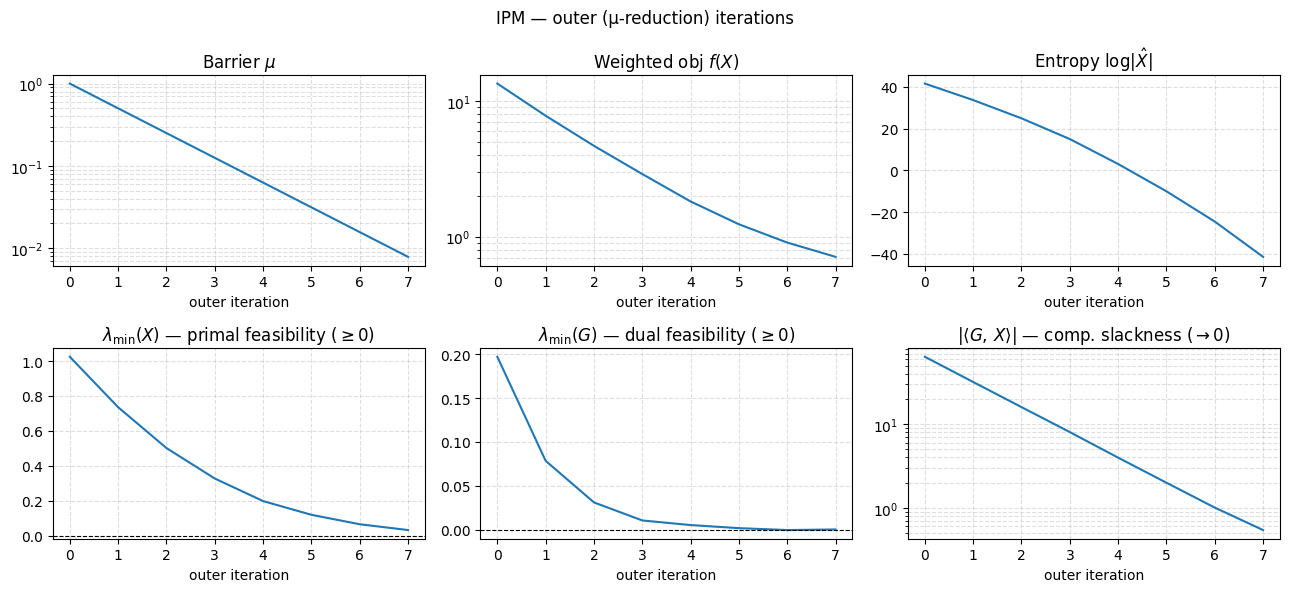

Total inner L-BFGS steps: 205

KKT residuals at final iterate:
  min eig X      = 3.220e-02   (≥ 0 required)
  min eig G      = 7.226e-05   (≥ 0 required)
  |⟨G, X⟩|       = 5.400e-01   (= 0 required)


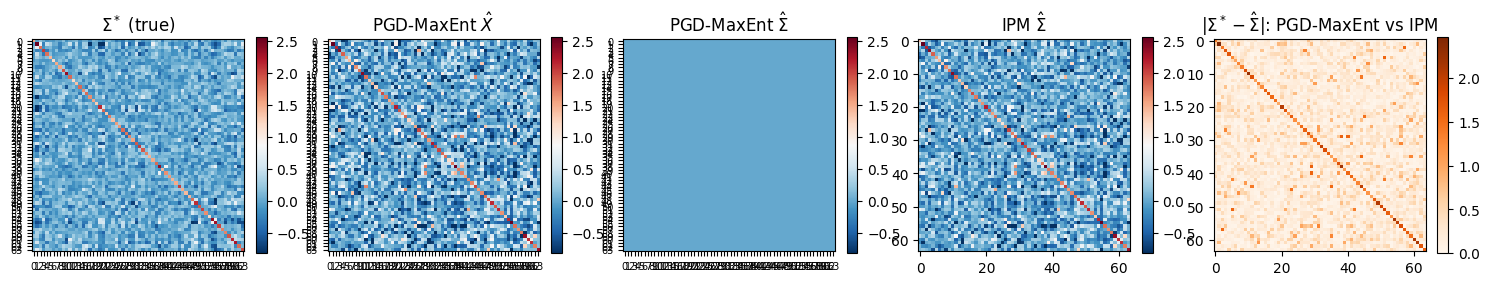

In [110]:
def ipm_diagnostics():
    iters_outer = range(len(hist_ipm))

    fig, axes = plt.subplots(2, 3, figsize=(13, 6))
    fig.suptitle("IPM — outer (μ-reduction) iterations", fontsize=12)

    # ── top row: optimisation progress ───────────────────────────────────────────
    axes[0, 0].semilogy(iters_outer, [h['mu']      for h in hist_ipm])
    axes[0, 0].set_title(r"Barrier $\mu$")

    axes[0, 1].semilogy(iters_outer, [h['obj']     for h in hist_ipm])
    axes[0, 1].set_title(r"Weighted obj $f(X)$")

    axes[0, 2].plot(iters_outer, [h['entropy']     for h in hist_ipm])
    axes[0, 2].set_title(r"Entropy $\log|\hat X|$")

    # ── bottom row: KKT residuals (same convention as Stage A) ───────────────────
    min_eig_X  = [h['min_eig_X']  for h in hist_ipm]
    min_eig_G  = [h['min_eig_G']  for h in hist_ipm]
    comp_slack = [h['comp_slack'] for h in hist_ipm]

    axes[1, 0].plot(iters_outer, min_eig_X)
    axes[1, 0].axhline(0, color='k', linewidth=0.8, linestyle='--')
    axes[1, 0].set_title(r"$\lambda_{\min}(X)$ — primal feasibility ($\geq 0$)")

    axes[1, 1].plot(iters_outer, min_eig_G)
    axes[1, 1].axhline(0, color='k', linewidth=0.8, linestyle='--')
    axes[1, 1].set_title(r"$\lambda_{\min}(G)$ — dual feasibility ($\geq 0$)")

    axes[1, 2].semilogy(iters_outer, np.maximum(comp_slack, 1e-16))
    axes[1, 2].set_title(r"$|\langle G,\,X\rangle|$ — comp. slackness ($\to 0$)")

    for ax in axes.flat:
        ax.set_xlabel("outer iteration")
        ax.grid(True, which='both', linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()

    print(f"Total inner L-BFGS steps: {sum(h['inner_iters'] for h in hist_ipm)}")
    print("\nKKT residuals at final iterate:")
    print(f"  min eig X      = {min_eig_X[-1]:.3e}   (≥ 0 required)")
    print(f"  min eig G      = {min_eig_G[-1]:.3e}   (≥ 0 required)")
    print(f"  |⟨G, X⟩|       = {comp_slack[-1]:.3e}   (= 0 required)")

    # ── Side-by-side error comparison ─────────────────────────────────────────────
    vmin = Sigma_true.min()
    vmax = Sigma_true.max()
    err_pgd = np.abs(Sigma_true - Sigma_hat)
    err_ipm = np.abs(Sigma_true - Sigma_ipm)
    emax = max(err_pgd.max(), err_ipm.max())
    delta_pgd_ipm = np.abs(err_pgd - err_ipm)
    delta_max = delta_pgd_ipm.max()

    fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))

    im0 = axes[0].imshow(Sigma_true, vmin=vmin, vmax=vmax, cmap='RdBu_r')
    axes[0].set_title(r"$\Sigma^*$ (true)")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    im1 = axes[1].imshow(X_hat, vmin=vmin, vmax=vmax, cmap='RdBu_r')
    axes[1].set_title(r"PGD-MaxEnt $\hat X$")
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    im2 = axes[2].imshow(Sigma_hat, vmin=vmin, vmax=vmax, cmap='RdBu_r')
    axes[2].set_title(r"PGD-MaxEnt $\hat\Sigma$")
    plt.colorbar(im2, ax=axes[2], fraction=0.046)

    im3 = axes[3].imshow(Sigma_ipm, vmin=vmin, vmax=vmax, cmap='RdBu_r')
    axes[3].set_title(r"IPM $\hat\Sigma$")
    plt.colorbar(im3, ax=axes[3], fraction=0.046)

    im4 = axes[4].imshow(delta_pgd_ipm, cmap='Oranges', vmin=0, vmax=delta_max)
    axes[4].set_title(r"$|\Sigma^* - \hat\Sigma|$: PGD-MaxEnt vs IPM")
    plt.colorbar(im4, ax=axes[4], fraction=0.046)

    # im4 = axes[4].imshow(np.hstack([err_pgd, err_ipm]), cmap='Oranges', vmin=0, vmax=emax)
    # axes[3].set_title(r"$|\Sigma^* - \hat\Sigma|$: PGD-MaxEnt | IPM")
    # plt.colorbar(im3, ax=axes[3], fraction=0.046)

    for ax in axes[:3]:
        ax.set_xticks(range(d)); ax.set_yticks(range(d)); ax.tick_params(labelsize=7)

    plt.tight_layout()
    plt.show()

ipm_diagnostics()

## Sparse Precision Optimizer

Minimize $f(X_E)$ over $z = (K_{ij})_{(i,j)\in E}$ where $K = X^{-1}$.

**Forward:** $z \to K \to X = K^{-1} \to x_E$

**Loss:** $f(x_E)$, same as Stage A

**Gradient:** $\nabla_z \ell = -\mathrm{mult} \cdot (XGX)_E$, computed automatically by JAX autodiff through `jnp.linalg.inv`.

**$K \succ 0$ enforcement:** `loss_fn` returns $10^{30}$ when $\mathrm{sign}(\det K) \le 0$ (via `jnp.linalg.slogdet`), causing the backtracking line search to reject the step and contract.  No barrier, no annealing.

**Max-entropy property:** any $X = K^{-1}$ with $K$ supported on $E$ is automatically the max-entropy completion with those covariance entries — the constraint is built into the parameterisation.

In [130]:
def sparse_prec_maxent(A, inds, tau,
                       mu_init=1.0, mu_factor=0.3, eps=1e-6, eps_coarse=1e-2,
                       max_inner=200, max_outer=50):
    """
    IPM variant of sparse precision optimizer.

    Minimizes  f(X_E) + mu * log|K|  over z = (K_ij)_{(i,j)∈E}, where K = X^{-1}.
    The term +mu*log|K| = -mu*log|X| is the log-barrier for X ≻ 0 (equivalently K ≻ 0),
    and also acts as entropy regularization.  As mu→0 the solution approaches the
    unconstrained minimizer of f.

    Outer loop: geometric schedule mu *= mu_factor, stopping when mu <= eps.
    Inner loop: L-BFGS with backtracking; tolerance = min(mu, eps_coarse).
      - At large mu the inner problem is solved coarsely (to eps_coarse): no benefit
        in over-solving since the central-path point is far from the final solution.
      - At small mu the tolerance tightens to mu, tracking the central path accurately.

    Non-PD steps are still rejected via jax.lax.cond returning 1e30.
    Cholesky is used for both logdet and the inverse (more stable than slogdet+inv).

    Parameters
    ----------
    eps        : final convergence tolerance (inner gtol at last outer level)
    eps_coarse : coarse inner tolerance for early outer levels (default 1e-2)
    """
    d = A.shape[0]
    rows, cols = inds[:, 0], inds[:, 1]
    diag_mask = rows == cols

    w      = 1.0 / tau**2;  w = w / w.max()
    rows_j = jnp.array(rows)
    cols_j = jnp.array(cols)
    w_j    = jnp.array(w)
    A_j    = jnp.array(A)

    def build_K(z):
        K = jnp.zeros((d, d))
        K = K.at[rows_j, cols_j].set(z)
        K = K.at[cols_j, rows_j].set(z)
        return K

    def loss_fn(z, mu):
        K = build_K(z)
        L = jnp.linalg.cholesky(K)      # NaN diagonal if K not PD
        chol_ok = jnp.all(jnp.isfinite(jnp.diag(L)))

        def valid(_):
            logdet_K = 2.0 * jnp.sum(jnp.log(jnp.diag(L)))
            X = jax.scipy.linalg.cho_solve((L, True), jnp.eye(d))
            r = X[rows_j, cols_j] - A_j[rows_j, cols_j]
            return jnp.sum(w_j * r**2) + mu * logdet_K

        def invalid(_):
            return jnp.array(1e30)

        return jax.lax.cond(chol_ok, valid, invalid, None)

    opt = optax.chain(
        optax.lbfgs(),
        optax.scale_by_zoom_linesearch(max_linesearch_steps=30),
    )

    @jax.jit
    def step(z, state, mu):
        loss = lambda z: loss_fn(z, mu)
        v, g = jax.value_and_grad(loss)(z)
        updates, new_state = opt.update(g, state, z, value=v, grad=g, value_fn=loss)
        z_new = optax.apply_updates(z, updates)
        return z_new, new_state, v, g

    z0   = jnp.array(np.where(diag_mask, 1.0 / np.maximum(A[rows, cols], 1e-6), 0.0))
    z    = z0
    hist = []
    mu   = float(mu_init)

    for _outer in range(max_outer):
        state      = opt.init(z)          # reset L-BFGS curvature history for new mu
        mu_j       = jnp.array(mu)
        inner_tol  = min(mu, eps_coarse)  # coarse early, tight late
        inner_iters = 0

        for _ in range(max_inner):
            z, state, v, g = step(z, state, mu_j)
            gnorm = float(jnp.linalg.norm(g))
            hist.append({'mu': mu, 'obj': float(v), 'grad_norm': gnorm})
            inner_iters += 1
            if gnorm < inner_tol:
                break

        print('  outer iter {:2d} | inner iter {:3d} | mu = {:.2e} | obj = {:.4e} | grad norm = {:.2e}'.format(
                _outer, inner_iters, mu, float(v), gnorm))
        hist[-1]['inner_iters'] = inner_iters  # annotate last entry of this level

        if mu <= eps:
            break
        mu *= mu_factor

    z_np  = np.array(z)
    K_opt = np.zeros((d, d))
    K_opt[rows, cols] = z_np
    K_opt[cols, rows] = z_np
    return project_psd(np.linalg.inv(K_opt)), hist


In [143]:
Sigma_sp, hist_sp = sparse_prec_maxent(A, inds, tau, mu_init=1e-10, eps=1e-10, max_inner=20000)

  outer iter  0 | inner iter 20000 | mu = 1.00e-10 | obj = 5.5444e-01 | grad norm = 3.21e-02


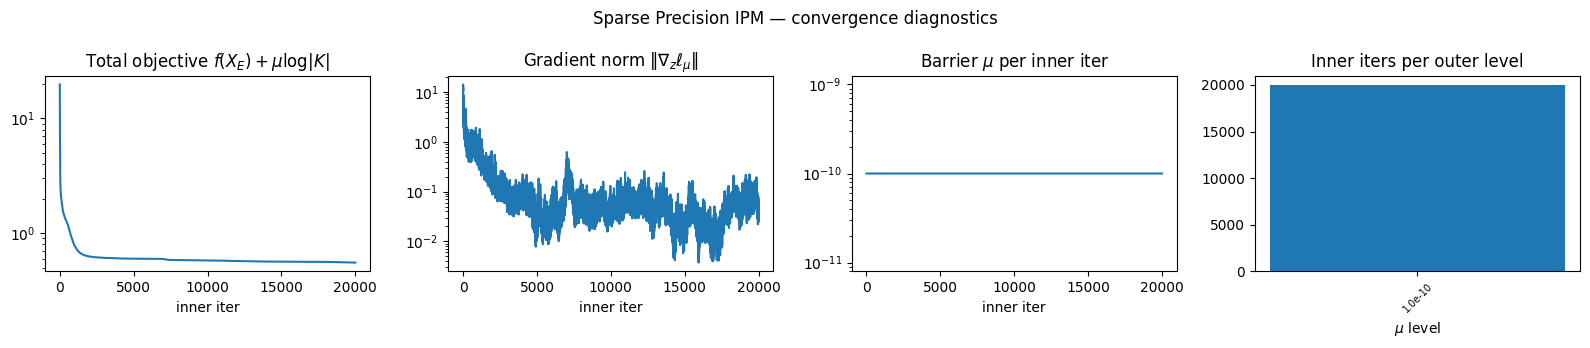

In [145]:
def sparse_prec_diagnostics():
    mus      = [h['mu']        for h in hist_sp]
    obj_sp   = [h['obj']       for h in hist_sp]
    gnorm_sp = [h['grad_norm'] for h in hist_sp]

    # outer-level summary: entries where inner_iters was recorded
    outer_entries = [(i, h) for i, h in enumerate(hist_sp) if 'inner_iters' in h]
    outer_mus     = [h['mu']          for _, h in outer_entries]
    outer_iters   = [h['inner_iters'] for _, h in outer_entries]

    # boundaries where mu changes (for vertical reference lines)
    boundaries = [i for i in range(1, len(mus)) if mus[i] != mus[i-1]]

    fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
    fig.suptitle("Sparse Precision IPM — convergence diagnostics", fontsize=12)

    iters = range(len(hist_sp))

    axes[0].semilogy(iters, obj_sp)
    for b in boundaries:
        axes[0].axvline(b, color='grey', lw=0.7, ls='--')
    axes[0].set_title(r"Total objective $f(X_E) + \mu\log|K|$")
    axes[0].set_xlabel("inner iter")

    axes[1].semilogy(iters, gnorm_sp)
    for b in boundaries:
        axes[1].axvline(b, color='grey', lw=0.7, ls='--')
    axes[1].set_title(r"Gradient norm $\|\nabla_z \ell_\mu\|$")
    axes[1].set_xlabel("inner iter")

    axes[2].semilogy(iters, mus)
    axes[2].set_title(r"Barrier $\mu$ per inner iter")
    axes[2].set_xlabel("inner iter")

    axes[3].bar(range(len(outer_mus)), outer_iters)
    axes[3].set_xticks(range(len(outer_mus)))
    axes[3].set_xticklabels([f'{m:.1e}' for m in outer_mus], rotation=45, fontsize=7)
    axes[3].set_title("Inner iters per outer level")
    axes[3].set_xlabel(r"$\mu$ level")

    fig.tight_layout()
    plt.show()

sparse_prec_diagnostics()


## Comparison

  Metric                            Stage A   PGD-MaxEnt     IPM-Chol  Sparse Prec
----------------------------------------------------------------------------------
  Weighted obj f(X)                  0.4706     230.9800       0.7080       0.5544
  Frobenius error                   28.8193      19.9462      26.0536      28.7980
  Entropy log|Σ̂|                 -746.6105   -4643.5217     -41.4215     -75.8853
  Min eigenvalue                     0.0000      -0.0000       0.0322       0.0168

  IPM-Chol:     8 outer iters, 205 total inner L-BFGS steps
  Sparse Prec:  20000 L-BFGS iters  grad_norm=3.21e-02


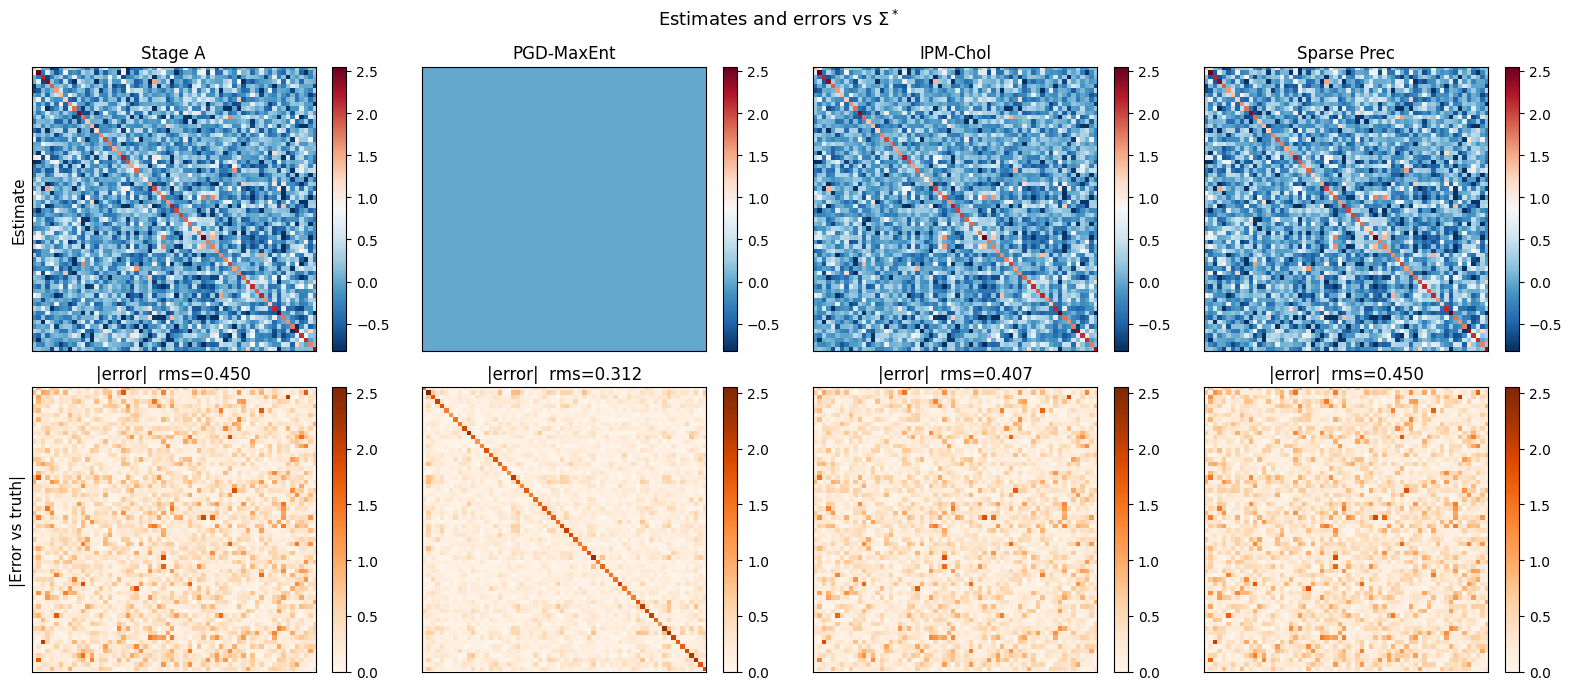

In [144]:
def compare():

    w_norm = (1.0 / tau ** 2)
    w_norm = w_norm / w_norm.max()

    def weighted_obj(Sigma):
        r = Sigma[inds[:, 0], inds[:, 1]] - A[inds[:, 0], inds[:, 1]]
        return float(np.sum(w_norm * r ** 2))

    methods = {
        'Stage A':      X_hat,
        'PGD-MaxEnt':   Sigma_hat,
        'IPM-Chol':     Sigma_ipm,
        'Sparse Prec':  Sigma_sp,
    }

    metrics = [
        ("Weighted obj f(X)",   lambda S: weighted_obj(S)),
        ("Frobenius error",     lambda S: float(np.linalg.norm(Sigma_true - S, 'fro'))),
        ("Entropy log|Σ̂|",     lambda S: float(np.linalg.slogdet(S)[1])),
        ("Min eigenvalue",      lambda S: float(np.linalg.eigvalsh(S).min())),
    ]

    col_w = 13
    header = f"  {'Metric':<28}" + "".join(f"{k:>{col_w}}" for k in methods)
    print(header)
    print("-" * len(header))
    for label, fn in metrics:
        row = f"  {label:<28}"
        for S in methods.values():
            try:
                row += f"{fn(S):>{col_w}.4f}"
            except Exception:
                row += f"{'N/A':>{col_w}}"
        print(row)

    print()
    print(f"  IPM-Chol:     {len(hist_ipm)} outer iters, "
        f"{sum(h['inner_iters'] for h in hist_ipm)} total inner L-BFGS steps")
    print(f"  Sparse Prec:  {len(hist_sp)} L-BFGS iters  "
        f"grad_norm={hist_sp[-1]['grad_norm']:.2e}")
    

    fig, axes = plt.subplots(2, 4, figsize=(16, 7))

    vmin = Sigma_true.min()
    vmax = Sigma_true.max()
    emax = max(np.abs(Sigma_true - S).max() for S in methods.values())

    for col, (name, S) in enumerate(methods.items()):
        # Top row: estimated matrix
        im = axes[0, col].imshow(S, vmin=vmin, vmax=vmax, cmap='RdBu_r')
        axes[0, col].set_title(name)
        plt.colorbar(im, ax=axes[0, col], fraction=0.046)

        # Bottom row: absolute error vs Sigma_true
        err = np.abs(Sigma_true - S)
        im2 = axes[1, col].imshow(err, vmin=0, vmax=emax, cmap='Oranges')
        axes[1, col].set_title(f'|error|  rms={np.sqrt(np.mean(err**2)):.3f}')
        plt.colorbar(im2, ax=axes[1, col], fraction=0.046)

    axes[0, 0].set_ylabel('Estimate', fontsize=11)
    axes[1, 0].set_ylabel('|Error vs truth|', fontsize=11)

    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([])

    plt.suptitle(r'Estimates and errors vs $\Sigma^*$', fontsize=13)
    plt.tight_layout()
    plt.show()

compare()

In [ ]:
nrows = 4
digits = 8

block = slice(0, nrows), slice(0, nrows)

(Sigma_true[block].round(digits),
X_hat[block].round(digits),
Sigma_hat[block].round(digits),
Sigma_ipm[block].round(digits))

(array([[ 1.28013297, -0.11671934,  0.11497955,  0.09749676],
        [-0.11671934,  1.18368734,  0.1620115 , -0.1028531 ],
        [ 0.11497955,  0.1620115 ,  2.13297192,  0.24793642],
        [ 0.09749676, -0.1028531 ,  0.24793642,  1.22065536]]),
 array([[ 1.42423843, -0.88660729, -0.46979703,  0.02106272],
        [-0.88660729,  1.21398981,  0.74447534,  0.06886484],
        [-0.46979703,  0.74447534,  2.1334126 , -0.21169057],
        [ 0.02106272,  0.06886484, -0.21169057,  1.51530294]]),
 array([[-0.,  0., -0., -0.],
        [ 0., -0., -0., -0.],
        [-0., -0., -0., -0.],
        [-0., -0., -0., -0.]]),
 array([[ 1.42423173, -0.88648381, -0.49497648,  0.43798423],
        [-0.88648381,  1.21390873,  0.74277233, -0.32576542],
        [-0.49497648,  0.74277233,  2.13338066, -0.21279206],
        [ 0.43798423, -0.32576542, -0.21279206,  1.51529603]]))